In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import seaborn as sns

In [7]:
csv = pd.read_csv('../../data/processed/reg-szn/shooting.csv')
df = pd.DataFrame(csv)
df.columns

Index(['Unnamed: 0', 'Rk', 'Player', 'Age', 'Team', 'Pos', 'G', 'GS', 'MP',
       'FG%', 'Dist.', 'fga%_2P', 'fga%_0-3', 'fga%_3-10', 'fga%_10-16',
       'fga%_16-3P', 'fga%_3P', 'fg%_2P', 'fg%_0-3', 'fg%_3-10', 'fg%_10-16',
       'fg%_16-3P', 'fg%_3P', 'ast%_2P', 'ast%_3P', 'dunk_fga%', 'dunks_made',
       'corner_3pa%', 'corner_3p%', 'heave_att', 'heave_made', 'Awards',
       'player_id', 'FGA', 'fga_per36_0-3', 'fga_per36_3-10',
       'fga_per36_10-16', 'fga_per36_16-3P', 'fga_per36_3P'],
      dtype='str')

In [12]:
df = df.drop_duplicates(subset='player_id', keep='first')

# fga_per36_* is NaN only for players with 0 FGA so just replace with 0
# TODO: Think about different methods of NULL replacement.
per36_cols = ['fga_per36_0-3', 'fga_per36_3-10', 'fga_per36_10-16', 'fga_per36_16-3P', 'fga_per36_3P']
df[per36_cols] = df[per36_cols].fillna(0)

# TODO: Since we can't tell for fg% of players that have never taken a shot before, just fill
# with league average and figure it out later by incorporating other data
pct_cols = ['fg%_10-16', 'fg%_16-3P', 'fg%_3P', 'ast%_3P']
df[pct_cols] = df[pct_cols].fillna(df.loc[df['MP'] >= 500, pct_cols].mean())

df.isna().sum()[lambda s: s > 0]

fg%_2P           3
fg%_0-3         13
fg%_3-10        14
ast%_2P          8
corner_3pa%     35
corner_3p%      56
Awards         528
dtype: int64

In [15]:
X = df[['fga_per36_0-3', 'fga_per36_3-10', 'fga_per36_10-16', 'fga_per36_16-3P', 'fga_per36_3P']] 

# find ideal k, according to elbow, stagnation indicator.
inertias = []
K_range = range(1, 11)

# essentially just look through 1 - 11 number of clusters to see the ideal.
for k in K_range:
    # random_state: a random number for generation
    # n_init: number of different starting positions (since they matter for clustering)
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    inertias.append(kmeans.inertia_)

print(inertias)

[9413.306749700589, 5626.401303538098, 4425.970360789774, 3853.944429542297, 3473.9692406299605, 3193.1025835038117, 2942.8577330862477, 2721.0083807551764, 2556.8424397516255, 2441.664584440704]


Text(0.5, 0, 'Iterations')

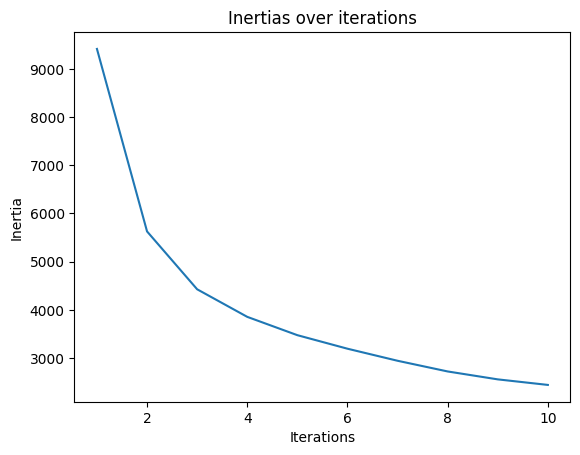

In [18]:
plt.plot(K_range, inertias)
plt.title('Inertias over iterations')
plt.ylabel('Inertia')
plt.xlabel('Iterations')
# Looks like 3 is the ideal inertia before stagnation.

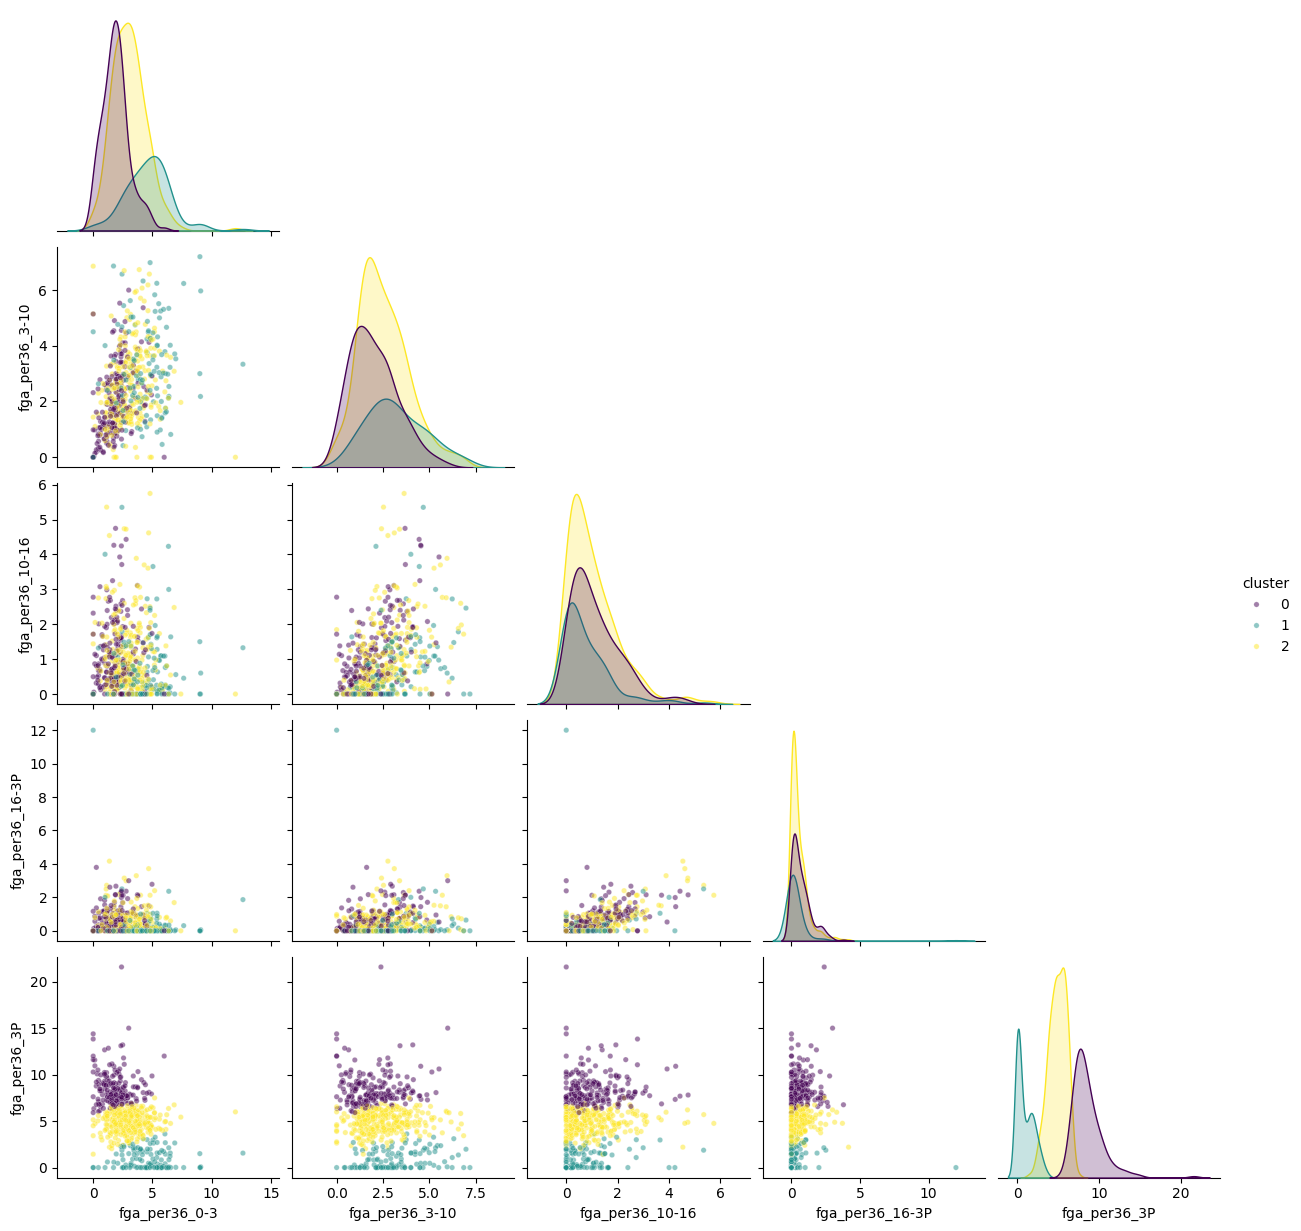

In [24]:
# Time to graph the actual clustering to see
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
y_kmeans = kmeans.fit_predict(X)
centroids = kmeans.cluster_centers_

plot_df = X.copy()
plot_df['cluster'] = y_kmeans

sns.pairplot(plot_df, hue='cluster', palette='viridis', corner=True,
             plot_kws={'alpha': 0.5, 's': 15})
plt.show()
# This graph seems to highlight the modern NBA perfectly. Nobody is really shooting
# long 2s. (16 - 3P), as they're highly deemed as inefficient. And we see the best
# reporesentation on 3P & 0-3 shooting, where most people will either go to the basket
# or shoot a 3. Represents the space and pace era perfectly.

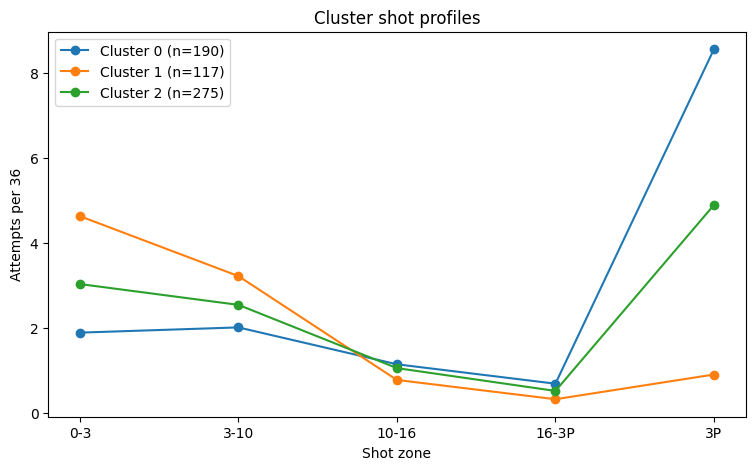

In [25]:
zones = [c.replace('fga_per36_', '') for c in X.columns]
cent = pd.DataFrame(centroids, columns=X.columns)

fig, ax = plt.subplots(figsize=(9, 5))
for i, row in cent.iterrows():
    ax.plot(zones, row.values, marker='o', label=f'Cluster {i} (n={sum(y_kmeans == i)})')
ax.set_xlabel('Shot zone')
ax.set_ylabel('Attempts per 36')
ax.set_title('Cluster shot profiles')
ax.legend()
plt.show()
# So it looks like orange is essentially just paint players that are slashers
# Green looks like an average player in the space and pace era- paint or 3 buckets
# Blue looks like volume 3 point shooters who thrive mostly on the line.

In [31]:
profile = pd.DataFrame(centroids.T, index=zones, columns = [f'Cluster {i}' for i in range(len(centroids))])
profile
# The exact values of the 3 different clusters

,Cluster 0,Cluster 1,Cluster 2
0-3,1.886209,4.624902,3.028464
3-10,2.009137,3.216098,2.539385
10-16,1.141821,0.774006,1.052223
16-3P,0.685563,0.320565,0.515437
3P,8.549687,0.901506,4.887468
